# Ujian Praktikum Data Science
## Hierarchical Clustering — Kelas A

## Nama: 'Muhammad Arif Hermawan', Nim: 123240063

### Ketentuan
- Kerjakan secara mandiri.
- Lakukan EDA dan pemeriksaan kualitas data.
- Tentukan fitur clustering sendiri.
- Jangan gunakan `CustomerID` sebagai fitur clustering.
- Bandingkan Ward, Average, Complete, dan Single.
- Gunakan Silhouette Score dan dendrogram.
- Interpretasikan hasil clustering melalui profil dan visualisasi.

## 1. Import Library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage, cophenet
from scipy.spatial.distance import pdist

## 2. Load Dataset

Muat dataset dan tampilkan beberapa baris pertama.

In [2]:
df = pd.read_csv('Customer_Segmentation_Dataset.csv')
display(df.head())

,Customer_ID,Age,Annual_Income_k,Spending_Score,Annual_Visits,Satisfaction_Score,Gender
0,C1269,50.222735,58.271149,25.586820,47.783589,4.342264,Male
1,C1074,27.945646,31.876336,25.061398,24.796354,4.751781,Female
2,C1290,51.253871,49.674105,17.082656,46.232911,5.694421,Male
3,C1156,23.434868,50.325701,93.794292,25.146269,7.614513,Female
4,C1105,22.527558,52.273892,68.660225,25.827519,7.105104,Male


## 3. Exploratory Data Analysis

Periksa shape, tipe data, missing value, duplicate, statistik deskriptif, distribusi, dan hubungan antarvariabel yang relevan.

In [3]:
print(f"Jumlah Baris: {df.shape[0]}")
print(f"Jumlah Kolom: {df.shape[1]}")

# missing value
print("\nMissing value:")
print(df.isna().sum())

# duplikat
print("\nData duplikat:")
print(df.duplicated().sum())

# statistik deskriptif
print("\nStatistik Deskriptif data:")
display(df.describe())

# analisis bivariat
groupped_by_gender = df.groupby("Gender")[['Age', 'Annual_Income_k', 'Spending_Score', 'Annual_Visits', 'Satisfaction_Score']].agg(['mean', 'median', 'std', 'min', 'max'])
display(groupped_by_gender)

Jumlah Baris: 503
Jumlah Kolom: 7

Missing value:
Customer_ID           0
Age                   3
Annual_Income_k       3
Spending_Score        2
Annual_Visits         2
Satisfaction_Score    2
Gender                0
dtype: int64

Data duplikat:
3

Statistik Deskriptif data:


,Age,Annual_Income_k,Spending_Score,Annual_Visits,Satisfaction_Score
count,500.000000,500.000000,501.000000,501.000000,501.000000
mean,36.455843,58.341992,54.351809,41.891681,6.050958
std,12.229294,19.593493,24.238433,16.562300,1.523493
min,18.000000,19.446758,5.552396,9.380521,2.733943
25%,24.148563,45.479525,30.114600,26.189082,4.863220
50%,38.245067,57.439310,55.204915,43.264369,6.097251
75%,46.290066,73.109736,78.685366,53.710477,7.242008
max,60.140627,102.562092,95.025656,105.000000,9.725762


Age                                        Annual_Income_k  \
             mean     median        std   min        max            mean   
Gender                                                                     
Female  35.901824  37.804264  12.117793  18.0  60.140627       58.682984   
Male    37.132977  38.987177  12.357451  18.0  58.596662       57.921841   

                                                     ... Annual_Visits  \
           median        std        min         max  ...          mean   
Gender                                               ...                 
Female  59.711430  20.158035  21.158842   96.343887  ...     41.845002   
Male    56.047731  18.911132  19.446758  102.562092  ...     41.948939   

                                                    Satisfaction_Score  \
           median        std        min         max               mean   
Gender                                                                   
Female  42.605627  17.191729   9.380521  105.000000           6.048993   
Male    44.674432  15.793841  11.434327   72.054662           6.053368   

                                                
          median       std       min       max  
Gender                                          
Female  6.200051  1.577837  2.862907  9.725762  
Male    5.918447  1.457557  2.733943  9.454389  

[2 rows x 25 columns]

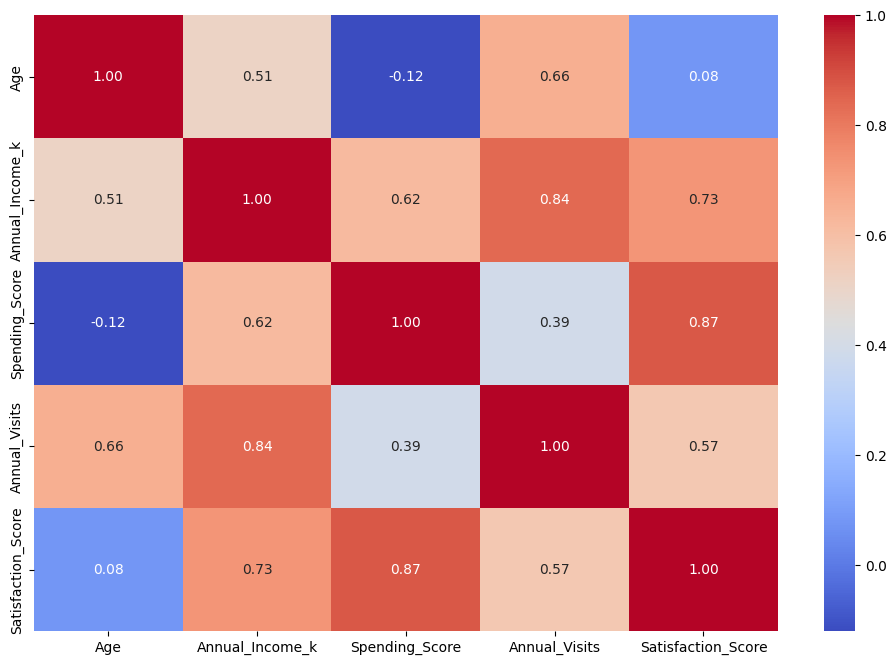

In [4]:
# analisis korelasi
continuous_feature = df[['Age', 'Annual_Income_k', 'Spending_Score', 'Annual_Visits', 'Satisfaction_Score']].corr()
plt.figure(figsize=(12, 8))
sns.heatmap(continuous_feature, annot=True, cmap='coolwarm', fmt='.2f')
plt.show()

## 4. Preprocessing

Periksa dan tangani masalah data jika diperlukan. Jelaskan singkat hasil pemeriksaan missing value dan duplicate.

In [5]:
# menangani missing value
clean_df = df.dropna()
print(f"Jumlah data setalah missing value ditangani: {clean_df.shape[0]}")

Jumlah data setalah missing value ditangani: 491


Terdapat beberapa missing value seperti yang telah dicek pada tahap EDA. dimana kolom berikut memiliki missing value
Age                   3
Annual_Income_k       3
Spending_Score        2
Annual_Visits         2
Satisfaction_Score    2
juga terdapat tiga data duplikat dalam dataset tersebut. Saya memilih untuk menghapus row yang ada missing value dan row duplikat karena apabila ditotal porsinya tidak signifikan dibanging jumlah seluruh baris data. Jumlah baris bersih menyisakan 491 baris.

In [6]:
# menangani data duplikat
clean_df = clean_df.drop_duplicates()
print(f"Jumlah data setalah data duplikat ditangani: {clean_df.shape[0]}")

Jumlah data setalah data duplikat ditangani: 488


## 5. Feature Selection

Tentukan fitur yang digunakan untuk clustering. **CustomerID tidak boleh digunakan.** Tuliskan alasan pemilihan fitur.

In [7]:
selected_feature = ['Age', 'Annual_Income_k', 'Spending_Score', 'Annual_Visits', 'Satisfaction_Score']
X = clean_df[selected_feature].copy()
display(X.sample(10))

,Age,Annual_Income_k,Spending_Score,Annual_Visits,Satisfaction_Score
13,18.927724,28.770955,37.798200,16.204337,3.584007
416,25.271952,48.014686,80.577709,32.102411,7.114611
111,45.698628,73.009155,62.927824,48.343708,6.282840
461,48.107981,72.683298,45.981518,45.346722,6.187028
424,40.361293,78.433885,57.772365,41.207523,6.472773
130,29.038657,30.377096,26.298752,15.513728,2.878422
253,54.784032,46.238534,30.490976,48.173392,5.848160
360,33.525854,70.123562,51.103762,44.972020,5.157891
133,49.541640,54.232257,33.259788,46.221274,5.395424
446,18.000000,48.597625,77.790069,29.429327,6.627984


## 6. Scaling

Lakukan standardisasi terhadap fitur final.

In [8]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=selected_feature, index=X.index)
display(X_scaled_df.head(10))

,Age,Annual_Income_k,Spending_Score,Annual_Visits,Satisfaction_Score
0,1.123021,-0.006604,-1.186460,0.351439,-1.124264
1,-0.704637,-1.361803,-1.208224,-1.044052,-0.854256
2,1.207618,-0.448006,-1.538729,0.257301,-0.232743
3,-1.074711,-0.414550,1.638911,-1.022810,1.033235
4,-1.149148,-0.314524,0.597778,-0.981453,0.697366
5,1.160136,-0.123756,-0.970462,0.691766,-0.428638
6,0.338387,1.611789,1.110555,1.264140,1.718538
7,-1.184257,0.018625,1.027128,-0.984794,1.061430
8,-1.079686,-1.527435,-1.320136,-1.305577,-1.542307
9,1.215014,-0.223430,-1.165023,0.774215,-0.545658


# HIERARCHICAL CLUSTERING

## 7. Agglomerative Clustering — 4 Linkage

Terapkan Ward, Average, Complete, dan Single. Hitung Silhouette Score untuk masing-masing.

In [9]:
n_clusters = 5

model_ward = AgglomerativeClustering(n_clusters=n_clusters, linkage='ward')
labels_ward = model_ward.fit_predict(X_scaled_df)
print(f"Label ward: {labels_ward[:10]}")

model_average = AgglomerativeClustering(n_clusters=n_clusters, linkage='average')
labels_average = model_average.fit_predict(X_scaled_df)
print(f"Label average: {labels_ward[:10]}")

model_complete = AgglomerativeClustering(n_clusters=n_clusters, linkage='complete')
labels_complete = model_complete.fit_predict(X_scaled_df)
print(f"Label complete: {labels_ward[:10]}")

model_single = AgglomerativeClustering(n_clusters=n_clusters, linkage='single')
labels_single = model_single.fit_predict(X_scaled_df)
print(f"Label single: {labels_ward[:10]}")

Label ward: [2 1 2 3 3 2 0 3 1 2]
Label average: [2 1 2 3 3 2 0 3 1 2]
Label complete: [2 1 2 3 3 2 0 3 1 2]
Label single: [2 1 2 3 3 2 0 3 1 2]


In [10]:
# silhouette score
silhouette_score_methods = []
for linkage_method, labels in {
    'ward': labels_ward,
    'average': labels_average,
    'complete': labels_complete,
    'single': labels_single
}.items():
    silhouette_avg = silhouette_score(X_scaled_df[selected_feature], labels)
    print(f"Siloutte score untuk linkage {linkage_method} adalah: {silhouette_avg:.4f}")
    silhouette_score_methods.append(silhouette_avg)

Siloutte score untuk linkage ward adalah: 0.5905
Siloutte score untuk linkage average adalah: 0.6258
Siloutte score untuk linkage complete adalah: 0.6255
Siloutte score untuk linkage single adalah: 0.2690


## 8. Perbandingan Silhouette Score

Buat tabel perbandingan hasil untuk keempat linkage.

In [11]:
methods = ['ward', 'average', 'complete', 'single']
comparison_table = pd.DataFrame({
    'Metode': methods,
    'Silhouette Score': silhouette_score_methods
})
display(comparison_table)

,Metode,Silhouette Score
0,ward,0.590520
1,average,0.625844
2,complete,0.625550
3,single,0.269014


## 9. Dendrogram — Ward

Buat dendrogram menggunakan Ward linkage.

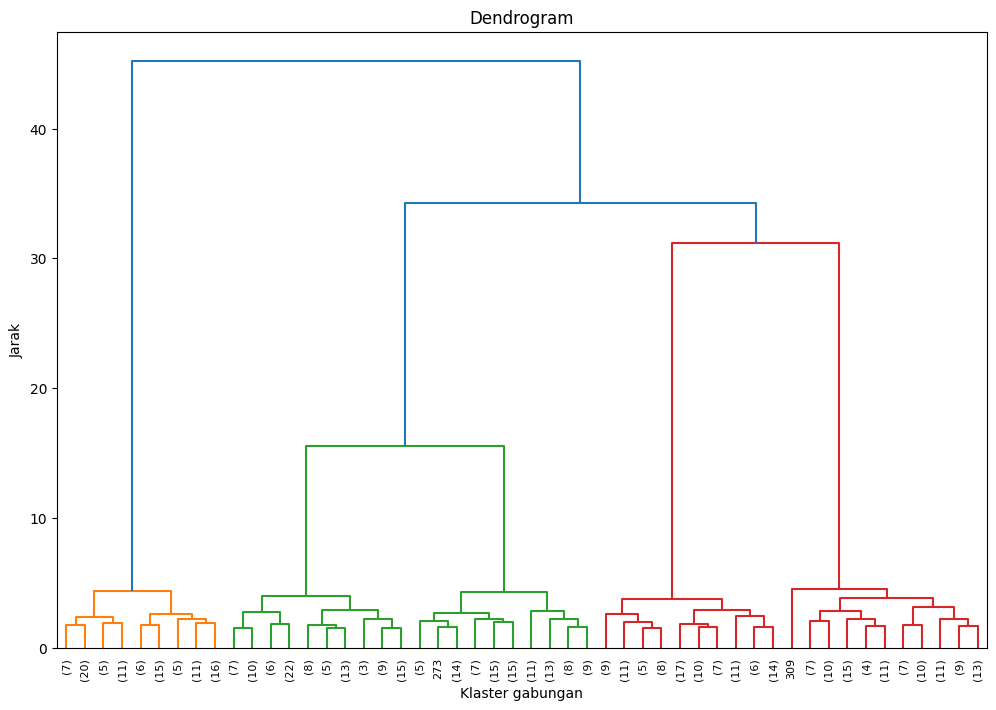

In [12]:
Z = linkage(X_scaled_df, method='ward', metric='euclidean')
plt.figure(figsize=(12, 8))
dendrogram(Z, leaf_rotation=90, truncate_mode='lastp', p=50)
plt.xlabel("Klaster gabungan")
plt.ylabel('Jarak')
plt.title('Dendrogram')
plt.show()

## 10. Menentukan Jumlah Cluster

Gunakan dendrogram dan hasil evaluasi untuk menentukan jumlah cluster yang paling wajar.

Ketinggian merge untuk membentuk k_target klaster: 4.5073
Ketinggian merge berikutnya: 15.5056
Maksimum jarak merge: 10.0064


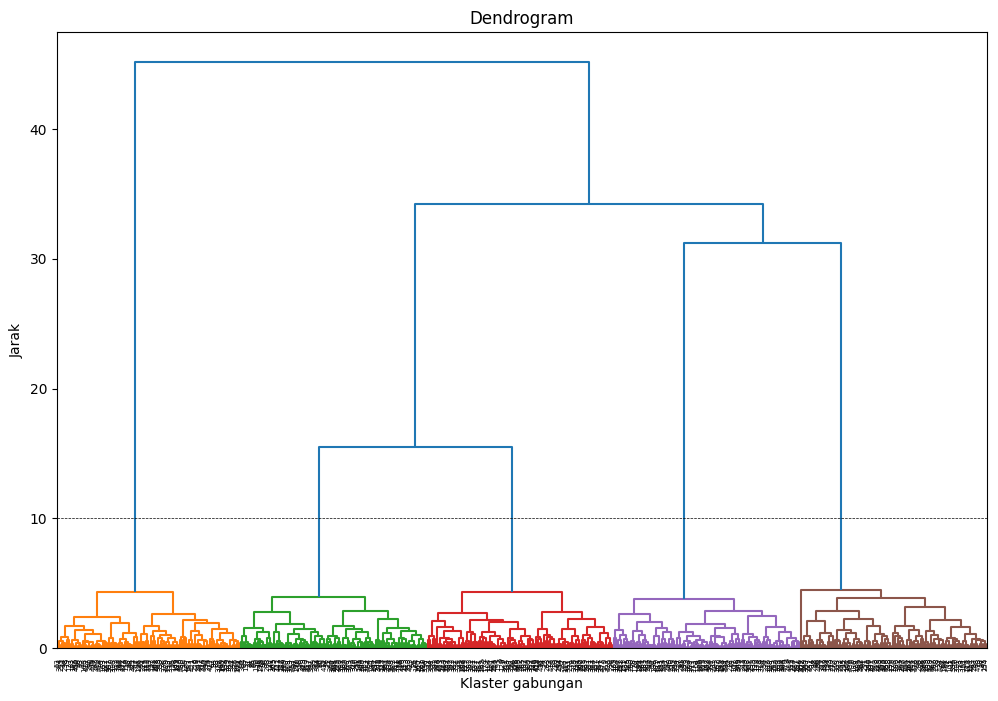

In [13]:
k_target = 5
n = X_scaled.shape[0]
idx_masuk_k = n - k_target - 1
idx_keluar_k = idx_masuk_k + 1
max_d = (Z[idx_masuk_k, 2] + Z[idx_keluar_k, 2]) / 2
print(f"Ketinggian merge untuk membentuk k_target klaster: {Z[idx_masuk_k, 2]:.4f}")
print(f"Ketinggian merge berikutnya: {Z[idx_keluar_k, 2]:.4f}")
print(f"Maksimum jarak merge: {max_d:.4f}")

plt.figure(figsize=(12, 8))
dendrogram(Z, show_leaf_counts=True, color_threshold=max_d)
plt.axhline(y=max_d, c='k', ls='--', lw='0.5')
plt.xlabel("Klaster gabungan")
plt.ylabel('Jarak')
plt.title('Dendrogram')
plt.show()

## 11. Profil Cluster

Buat tabel profil cluster berdasarkan nilai rata-rata fitur yang digunakan.

In [14]:
profile = (clean_df[selected_feature]
    .assign(Cluster=labels_ward)
    .groupby('Cluster')
    .mean()
    .round(2)
)

profile['Jumlah_Anggota'] = (
    pd.Series(labels_ward)
    .value_counts()
    .sort_index()
)

display(profile)

,Age,Annual_Income_k,Spending_Score,Annual_Visits,Satisfaction_Score,Jumlah_Anggota
Cluster,,,,,,
0,38.73,85.61,82.08,65.22,8.03,98
1,21.96,30.19,25.32,20.52,3.97,96
2,52.57,55.56,30.38,49.61,5.14,98
3,24.58,50.14,77.86,29.19,7.00,98
4,44.54,69.93,54.92,44.99,6.06,98


## 12. Visualisasi Hasil Clustering

Buat dua visualisasi untuk membantu interpretasi hasil clustering, yang terdiri dari:

1. scatter plot Annual Income dan Spending Score dengan warna berdasarkan cluster; dan
2. satu visualisasi tambahan yang sesuai, seperti boxplot atau heatmap profil cluster.

Kemudian jelaskan pola yang terlihat pada visualisasi tersebut.

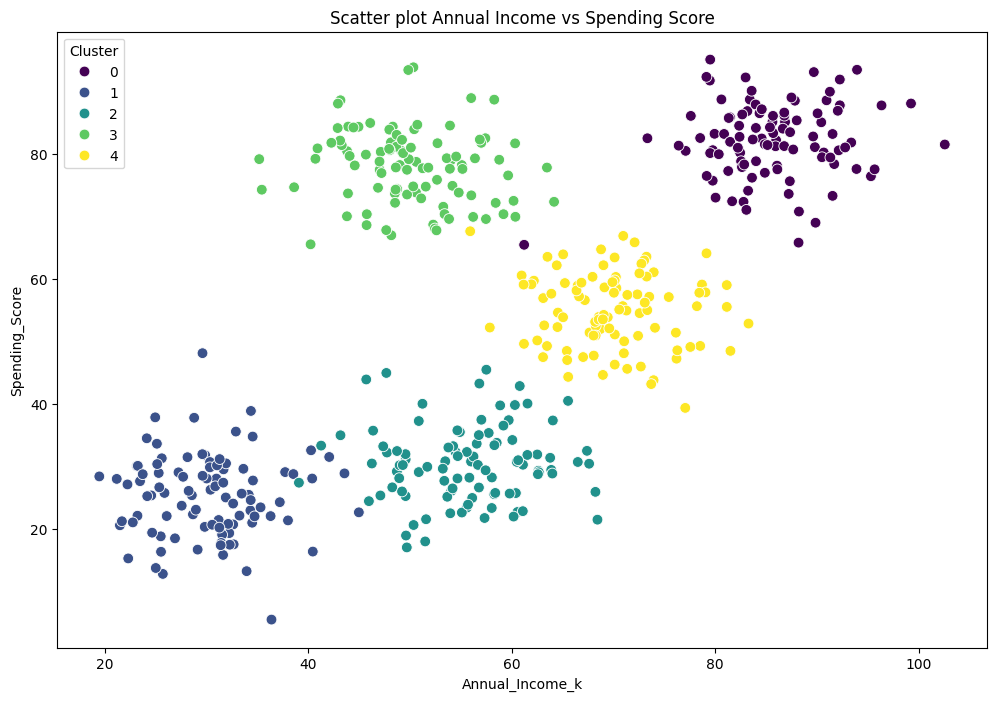

In [15]:
clean_df['Cluster'] = labels_ward
plt.figure(figsize=(12, 8))
sns.scatterplot(data=clean_df, x='Annual_Income_k', y='Spending_Score', hue="Cluster", palette='viridis', s=60)
plt.title('Scatter plot Annual Income vs Spending Score')
plt.show()

<Figure size 1200x800 with 0 Axes>

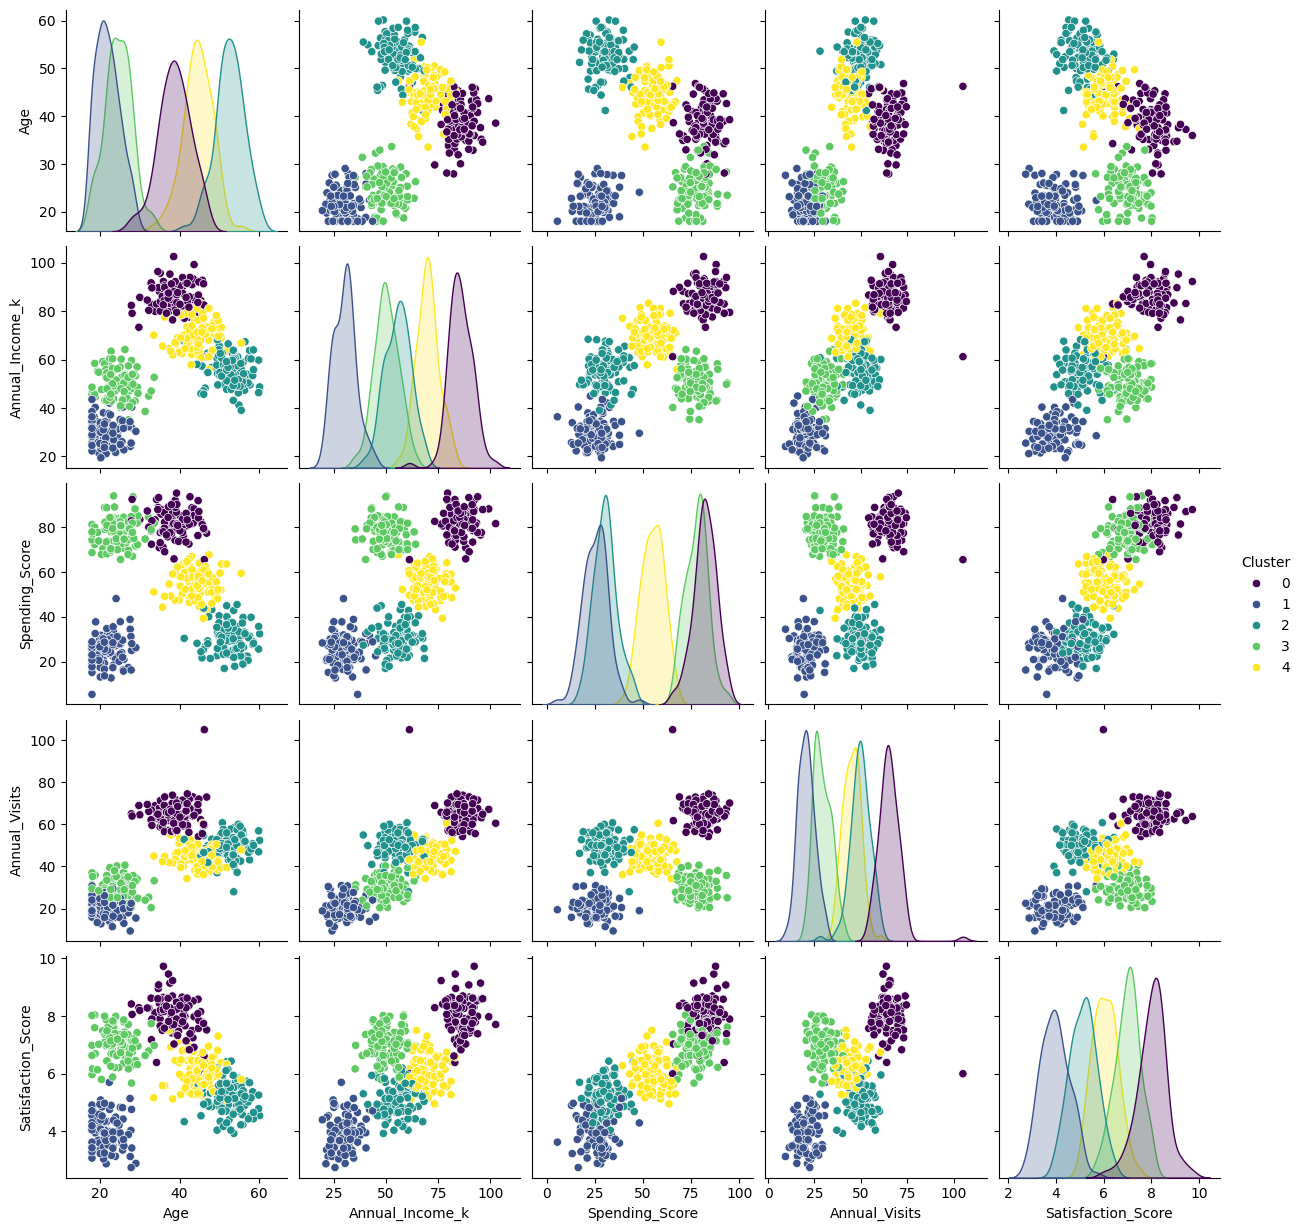

In [16]:
# pair plot
plt.figure(figsize=(12, 8))
sns.pairplot(clean_df, vars=selected_feature, palette='viridis', diag_kind='kde', hue='Cluster')
plt.show()

## 13. Analisis Visualisasi

Jelaskan pola yang terlihat: apakah cluster terpisah atau tumpang tindih, fitur yang paling membedakan, dan apakah visualisasi mendukung profil cluster.

Cluster relatif terpisah dengan sedikit perbatasan yang beririsan. Fitur yang paling membedakan dalam artian paling memngaruhi adalah spending score dimana representasi cluster yang dibangingkan dengan spending score memiliki pemisahan kluster yang lebih jelas daripada fitur lain. Visualisasi juga mendukung fitur klaster yang menghitung rata rata, dimana dalam representasi scatter plot dapat dihubungkan dengan titik tengah dari sebuah cluster yang mana bisa dilihat datanya akan saling mendukung, sebagai contoh kluster 1 memiliki average income 85.61	dan spending score 82.08 yang mana dari profil kluster itu merupakan yang tertinggi, dapat dilihat di scatter plot bahwa kluster 0 berada di pjok kanan atas yang mana pertemuan nilai-nilai tertinggi dari masing-masing sumbu.

# Pertanyaan Analisis

### 1.
Linkage mana yang menghasilkan Silhouette Score paling tinggi? Jelaskan apa yang dapat ditunjukkan oleh hasil tersebut.

Jawab:

Berdasarkan percobaan yang saya lakukan linkage Average menghasilkan silhoutte score yang paling tinggi sebesat 0.625844 diikuti oleh Complete dengan skor 0.625550, kemudian diikuti Ward dengan skor 0.590520, dan terakhir adalah methode Single sebesar 0.269014. Hasil tersebut menunjukkan bahwa metode menggunakan algoritma yang berbeda untuk menghitung silhouette score. Skor diatas 0.5 realtif tinggi atau jumlah cluster yang dipilih sudah cocok untuk digunakan. Saya mencoba menambah dan mengurangi jumlah cluster dan dari berbagai percobaan hasilnya adalah jumlah cluster 4 dan 5 adalah yang paling cocok digunakan, sementara diluar rentang tersebut silhoutte score menghasilkan angka yang lebih rendah.



### 2.
Berdasarkan dendrogram dan hasil evaluasi, berapa jumlah cluster yang menurutmu paling wajar? Jelaskan dasar pemilihannya.

Jawab:

Berdasarkan dendrogram dan hasil evaluasi, jumlah cluster yang paling masuk akal untuk diambil adalah 5 cluster, karena dengan 5 cluster saya melihat distribusi anggota sangat merata (Lihat no 10) di rentang 96 - 98, kemudian secara kasat mata dari dendrogram akan terlihat bahwa ada 5 kelompok yang jaraknya sangat rapat satu sama lain sebelum bergabung dengan kelompok lainnya melalui jarak yang sangat panjang. Maka atas pertimbangan distribusi anggota dan visualisasi dendrogram, kluster yang dipilih sebaiknya adalah 5 kluster.

### 3.
Berdasarkan profil dan visualisasi cluster, jelaskan karakteristik masing-masing cluster. Apa pola utama yang terlihat dan fitur apa yang paling membedakan cluster?

Jawab:

apabila setiap cluster dapat diberi nama, maka

- Kluster 0: income tinggi dan spending tinggi
kluster ini memiliki karakteristik sebagai orang kaya yang rajin berbelanja dalam porsi yang sangat besar, dapat dianggap akan selalu membali barang terbaru yang berharga relatif mahal

- Kluster 1: income rendah dan spending rendah
kluster ini memeiliki karakteristik sebagai masyarakat biasa yang berpenghasilan minimum dan membelanjakan dengan hati-hati, utamanya untuk bertahan hidup

- Kluster 2: income sedang dan spending rendah
kluster ini memiliki karakteristik sebagai orang yang berpenghasilan menengah namun memiliki perilaku spending yang hati-hati

- Kluster 3: income sedang dan spending tinggi
kluster ini memiliki karakteristik sebagai orang yang berpenghasilan menengah namun dengan perilaku spending yang sangat konsumtif

- Kluster 4: income sedang dan spending sedang
kluster ini memiliki karaktristik sebagai orang yang berpenghasilan menengah dan berbelanja secukupnya, tidak overspend sehingga akan menghabiskan pendapatan dengan cepat, juga tidk terlalu hemat

### 4. 
Apakah hasil clustering menunjukkan pemisahan kelompok yang cukup jelas? Jelaskan dengan menghubungkan Silhouette Score, dendrogram, dan visualisasi

Jawab:

hasil clustering menghasilkan pemisahan kelompok yang jelas, setidaknya untuk Annual Income dibandingkan dengan Spending Score. Dimulai dari silhoutte score dimana menghasilkan skor di rentang 0.5 - 0.6 yang dikatakan cukup dan memang rentang tertinggi untuk dataset ini dari berbagai percobaan. Dendrogram juga menunjukkan separasi distribusi yang sangat merata dan proporsional dimana ketinggian jarak antar kluster relatif sama. Untuk visualisasi scatter plot dan pair plot terlihat bahwa setiap cluster terpisah secara jelas, memang ada sedikit irisan-irisan di perbatasan antar cluster namun secara garis besar tetap terpisah secara jelas.